<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-/blob/main/DBSCAN_clustering_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**DBSCAN Clustering Algorithm**

**Overview**

Below is a step-by-step Machine Learning practical on DBSCAN (Density-Based Spatial Clustering of Applications with Noise) using the Iris dataset (an open-access dataset available in Scikit-learn). This experiment identifies clusters and noise points.

**Aim**

To implement the DBSCAN clustering algorithm on the Iris dataset and identify clusters and noise points.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN


In [2]:
iris = load_iris()

X = iris.data

print("Number of Samples :", X.shape[0])
print("Number of Features :", X.shape[1])


Number of Samples : 150
Number of Features : 4


In [4]:
df = pd.DataFrame(X, columns=iris.feature_names)
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])


[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [6]:
dbscan = DBSCAN(eps=0.8, min_samples=5)

clusters = dbscan.fit_predict(X_scaled)

print(clusters)


[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0
  0  0  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1 -1  1  1
  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1]


In [7]:
df["Cluster"] = clusters

print(df.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Cluster  
0        0  
1        0  
2        0  
3        0  
4        0  


In [8]:
print("Unique Cluster Labels")

print(df["Cluster"].unique())


Unique Cluster Labels
[ 0 -1  1]


In [9]:
noise = sum(clusters == -1)

print("Number of Noise Points :", noise)


Number of Noise Points : 4


#**Graph Explaination**

This graph represents the result of DBSCAN clustering applied to the standardized Iris dataset. The X-axis represents standardized sepal length and the Y-axis represents standardized sepal width. Different colors represent different cluster labels. The red and green points represent the clusters identified by DBSCAN, while the purple points represent noise or outliers, indicated by the label -1. With eps = 0.8 and min_samples = 5, DBSCAN identified two dense clusters and some noise points.


#**Graph element	Meaning**

🔴 Red	One DBSCAN cluster

🟢 Green	Another DBSCAN cluster

🟣 Purple	Noise / outlier

X-axis	Standardized Sepal Length

Y-axis	Standardized Sepal Width

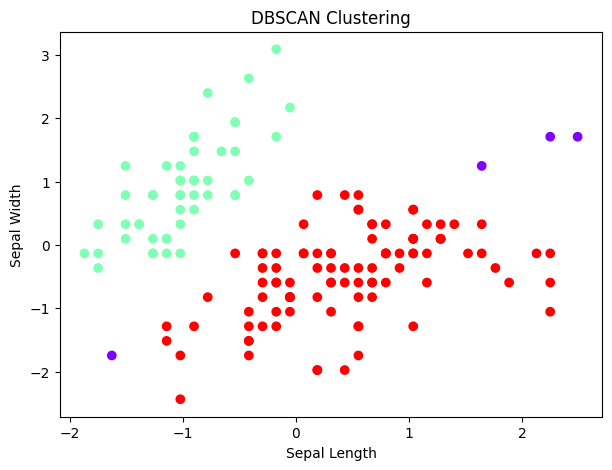

In [10]:
plt.figure(figsize=(7,5))

plt.scatter(X_scaled[:,0],
            X_scaled[:,1],
            c=clusters,
            cmap='rainbow')

plt.title("DBSCAN Clustering")

plt.xlabel("Sepal Length")

plt.ylabel("Sepal Width")

plt.show()


In [11]:
print(df)


     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                  5.1               3.5                1.4               0.2   
1                  4.9               3.0                1.4               0.2   
2                  4.7               3.2                1.3               0.2   
3                  4.6               3.1                1.5               0.2   
4                  5.0               3.6                1.4               0.2   
..                 ...               ...                ...               ...   
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149                5.9               3.0                5.1               1.8   

     Cluster  
0          0